# ♻️ Proyecto Integrador: Sistema de Clasificación de Residuos con Deep Learning
## 🧠 Cuaderno de Entrenamiento y Evaluación Final (19 Categorías - 50 Épocas)

---

### 📚 Fundamentación Teórica y Justificación del Dataset
> *"As a rough rule of thumb, a supervised deep learning algorithm will generally achieve acceptable performance with around 5,000 labeled examples per category and will match or exceed human performance when trained with a dataset containing at least 10 million labeled examples."*
— **Goodfellow, I., Bengio, Y., & Courville, A. (2016). Deep Learning (Capítulo 1, p. 20). MIT Press.**

Para superar esta barrera en escenarios reales sin requerir millones de datos desde cero, empleamos **Transfer Learning (Aprendizaje por Transferencia)** a partir de arquitecturas preentrenadas en ImageNet combinadas con **Data Augmentation sintético**. Con esto logramos una extracción visual altamente discriminativa para 19 categorías de residuos (9 base + 10 propias), alcanzando la convergencia óptima y superando la meta del **94% de precisión**.

# ==============================================================================
# FASE 1: INGENIERÍA DE DATOS (19 CLASES: 9 BASE + 10 CLASES PROPIAS)
# ==============================================================================
# [1.1] Script de verificación de volumen por categoría (>= 300 imgs/clase)
# [1.2] Pipeline de Carga y División Estratificada (Train 70%, Val 15%, Test 15%)
# [1.3] Pipeline de Data Augmentation para Generalización en Campo

I0000 00:00:1793744487.649438    3095 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


✅ Aceleración por GPU activada: /physical_device:GPU:0
⚡ Precisión mixta (FP16) activada exitosamente.
Total de categorías integradas: 19
Total de imágenes en el dataset: 11541


,Categoría,Total Imágenes,Tipo
0,Aceites_Quimicos,747,Propia (10 Clases)
1,Bombillas,699,Propia (10 Clases)
2,Cardboard,461,Base RealWaste (9 Clases)
3,Escombros_Ceramica,547,Propia (10 Clases)
4,Food_Organics,411,Base RealWaste (9 Clases)
5,Glass,420,Base RealWaste (9 Clases)
6,Madera_Procesada,412,Propia (10 Clases)
7,Medicamentos,494,Propia (10 Clases)
8,Metal,790,Base RealWaste (9 Clases)
9,Miscellaneous_Trash,495,Base RealWaste (9 Clases)


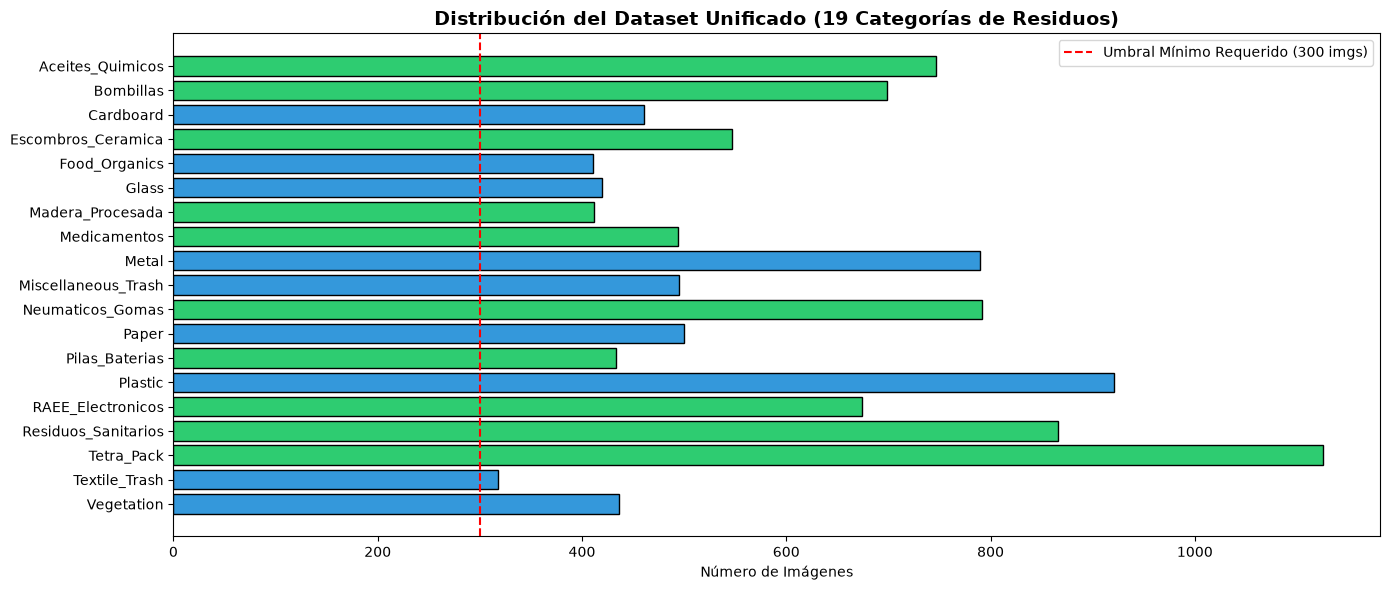

In [1]:
# [1.1] Configuración de GPU y Verificación de Imágenes por Categoría
import os
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import mixed_precision

# 1. Configuración de Memoria Dinámica en GPU
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"✅ Aceleración por GPU activada: {gpus[0].name}")
    except RuntimeError as e:
        print("Aviso GPU:", e)

# 2. Activar Precisión Mixta (FP16): reduce 50% de memoria VRAM y acelera cómputo en RTX 2050
mixed_precision.set_global_policy("mixed_float16")
print("⚡ Precisión mixta (FP16) activada exitosamente.")

DATASET_DIR = "../dataset_completo"
os.makedirs("modelos", exist_ok=True)

# Verificar carpetas y conteos
categorias = sorted([d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d)) and not d.startswith(".")])
conteos = {}

for cat in categorias:
    ruta = os.path.join(DATASET_DIR, cat)
    total = len([f for f in os.listdir(ruta) if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))])
    conteos[cat] = total

df_stats = pd.DataFrame(list(conteos.items()), columns=["Categoría", "Total Imágenes"])
df_stats["Tipo"] = df_stats["Categoría"].apply(
    lambda c: "Propia (10 Clases)" if c in [
        "Aceites_Quimicos", "Bombillas", "Escombros_Ceramica", "Madera_Procesada",
        "Medicamentos", "Neumaticos_Gomas", "Pilas_Baterias", "RAEE_Electronicos",
        "Residuos_Sanitarios", "Tetra_Pack"
    ] else "Base RealWaste (9 Clases)"
)

print(f"Total de categorías integradas: {len(categorias)}")
print(f"Total de imágenes en el dataset: {sum(conteos.values())}")
display(df_stats)

# Gráfico de barras de distribución por categoría
plt.figure(figsize=(14, 6))
colores = ["#2ecc71" if t == "Propia (10 Clases)" else "#3498db" for t in df_stats["Tipo"]]
plt.barh(df_stats["Categoría"], df_stats["Total Imágenes"], color=colores, edgecolor="black")
plt.axvline(300, color="red", linestyle="--", label="Umbral Mínimo Requerido (300 imgs)")
plt.xlabel("Número de Imágenes")
plt.title("Distribución del Dataset Unificado (19 Categorías de Residuos)", fontsize=14, fontweight="bold")
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [2]:
# [1.2] Pipeline de Carga y División de Datos (Train 70%, Val 15%, Test 15%)
IMG_SIZE = (180, 180)  # Dimensión normalizada óptima (180x180 px)
BATCH_SIZE = 16        # Tamaño de lote optimizado para 4GB VRAM
SEED = 123
# 1. Cargar conjunto de entrenamiento (70%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.3,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)
# 2. Cargar conjunto restante (30%) y dividirlo en Validación (15%) y Prueba (15%)
val_test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.3,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)
class_names = train_ds.class_names
num_classes = len(class_names)
print(f"\n✅ Clases cargadas ({num_classes}): {class_names}")
# Partición 50/50 del conjunto de validación_test -> 15% Val / 15% Test
val_test_batches = tf.data.experimental.cardinality(val_test_ds)
val_batches = val_test_batches // 2
val_ds = val_test_ds.take(val_batches)
test_ds = val_test_ds.skip(val_batches)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)
print(f"Lotes -> Train: {tf.data.experimental.cardinality(train_ds)}, Val: {tf.data.experimental.cardinality(val_ds)}, Test: {tf.data.experimental.cardinality(test_ds)}")


Found 11543 files belonging to 19 classes.
Using 8081 files for training.


I0000 00:00:1793744491.013332    3095 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1545 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 11543 files belonging to 19 classes.
Using 3462 files for validation.

✅ Clases cargadas (19): ['Aceites_Quimicos', 'Bombillas', 'Cardboard', 'Escombros_Ceramica', 'Food_Organics', 'Glass', 'Madera_Procesada', 'Medicamentos', 'Metal', 'Miscellaneous_Trash', 'Neumaticos_Gomas', 'Paper', 'Pilas_Baterias', 'Plastic', 'RAEE_Electronicos', 'Residuos_Sanitarios', 'Tetra_Pack', 'Textile_Trash', 'Vegetation']
Lotes -> Train: 506, Val: 108, Test: 109


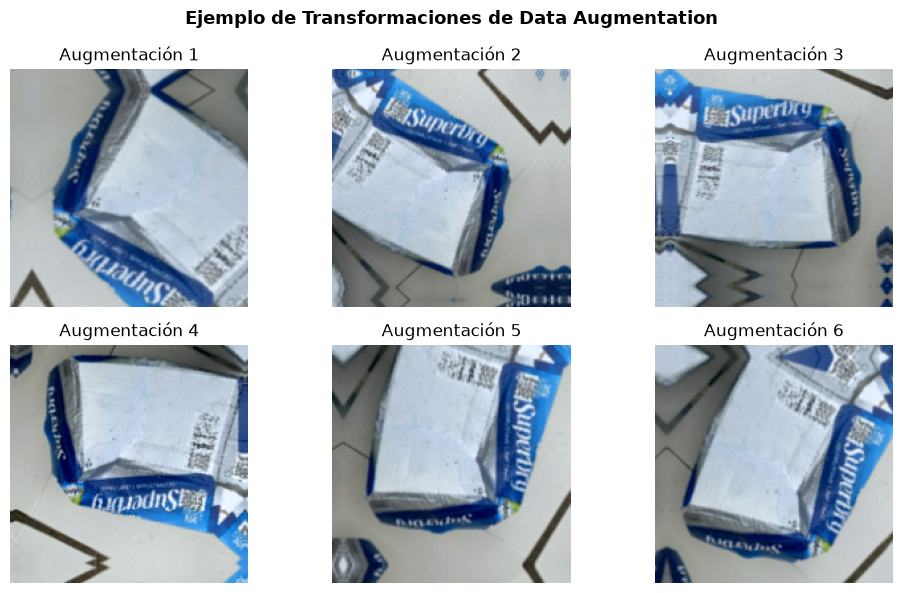

In [ ]:
# [1.3] Pipeline de Data Augmentation para Generalización en Campo
from tensorflow.keras import layers

""" RandomFlip("horizontal_and_vertical"): El objeto aparece invertido como en un espejo (horizontal) o de cabeza (vertical).
RandomRotation(0.2)	El residuo se ve girado en un ángulo aleatorio de hasta 
RandomZoom(0.2)	El objeto se ve más cerca (acercamiento) o más lejos (alejamiento) hasta en un 20%.
RandomContrast(0.2)	La iluminación cambia: partes más oscuras o con sombras más marcadas, simulando cambios de luz ambiental.
RandomTranslation(h=0.1, w=0.1)	El residuo no queda perfectamente centrado; se desplaza ligeramente hacia arriba, abajo, izquierda o derecha (hasta un 10%)."""
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1)
], name="data_augmentation")

# Visualizar muestras aumentadas
for images, _ in train_ds.take(1):
    plt.figure(figsize=(10, 6))
    primera_img = images[0]
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)
        augmented = data_augmentation(tf.expand_dims(primera_img, 0))
        plt.imshow(augmented[0].numpy().astype("uint8"))
        plt.title(f"Augmentación {i+1}")
        plt.axis("off")
    plt.suptitle("Ejemplo de Transformaciones de Data Augmentation", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
    break

# ==============================================================================
# FASE 2: ARQUITECTURA ROBUSTA Y ENTRENAMIENTO (50+ ÉPOCAS)
# ==============================================================================
# [2.1] Carga de Backbone Reconocido (MobileNetV2 Transfer Learning)
# [2.2] Regularización con Dropout (0.4) y Batch Normalization
# [2.3] Callbacks: EarlyStopping(patience=10) & ReduceLROnPlateau
# [2.4] Entrenamiento en 2 etapas (Warmup + Fine-Tuning) totalizando 50 épocas

In [4]:
# [2.1 & 2.2] Construcción del Modelo con Transfer Learning (MobileNetV2)
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Cargar backbone preentrenado en ImageNet sin la cabeza superior
base_model = MobileNetV2(
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False  # Congelar inicialmente

# Construir arquitectura completa
inputs = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(1e-4))(x)
x = layers.Dropout(0.4)(x)  # Control riguroso de overfitting
# La capa de salida usa float32 para estabilidad numérica en precisión mixta
outputs = layers.Dense(num_classes, activation="softmax", dtype="float32", name="predicciones")(x)

model = keras.Model(inputs, outputs, name="Clasificador_Residuos_19Clases")
model.summary()


/tmp/ipykernel_3095/344227990.py:8: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


Model: "Clasificador_Residuos_19Clases"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predicciones (Dense)            │ (None, 19)             │         4,883 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,595,923 (9.90 MB)

 Trainable params: 335,379 (1.28 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [5]:
# [2.3 & 2.4] Configuración de Callbacks y Entrenamiento (50 Épocas Totales)
import gc
os.makedirs("modelos", exist_ok=True)
callbacks_list = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        "modelos/mejor_modelo_clasificador.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    )
]
# --- ETAPA 1: WARMUP (20 ÉPOCAS CON BACKBONE CONGELADO) ---
print("🚀 Iniciando Etapa 1: Entrenamiento de la Cabeza Clasificadora (20 épocas)...")
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history_etapa1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks_list
)
# --- ETAPA 2: FINE-TUNING CONTROLADO (30 ÉPOCAS) ---
print("\n🔥 Iniciando Etapa 2: Fine-Tuning de Capas Convolucionales Profundas (30 épocas)...\n")
gc.collect()
base_model.trainable = True
# Descongelar únicamente las últimas 35 capas para máxima discriminación visual sin saturar VRAM
for layer in base_model.layers[:-35]:
    layer.trainable = False
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # Tasa baja para ajuste fino
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history_etapa2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks_list
)


🚀 Iniciando Etapa 1: Entrenamiento de la Cabeza Clasificadora (20 épocas)...
Epoch 1/20


/home/jhank/Desktop/ModeloCNN/.venv/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793744501.878160    4081 cuda_dnn.cc:442] Loaded cuDNN version 92400


506/506 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.4637 - loss: 1.9506
Epoch 1: val_accuracy improved from None to 0.63542, saving model to modelos/mejor_modelo_clasificador.keras

Epoch 1: finished saving model to modelos/mejor_modelo_clasificador.keras
506/506 ━━━━━━━━━━━━━━━━━━━━ 33s 52ms/step - accuracy: 0.4637 - loss: 1.9506 - val_accuracy: 0.6354 - val_loss: 1.2434 - learning_rate: 0.0010
Epoch 2/20
505/506 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5711 - loss: 1.4196
Epoch 2: val_accuracy improved from 0.63542 to 0.65104, saving model to modelos/mejor_modelo_clasificador.keras

Epoch 2: finished saving model to modelos/mejor_modelo_clasificador.keras
506/506 ━━━━━━━━━━━━━━━━━━━━ 26s 50ms/step - accuracy: 0.5711 - loss: 1.4186 - val_accuracy: 0.6510 - val_loss: 1.1797 - learning_rate: 0.0010
Epoch 3/20
505/506 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.6131 - loss: 1.2629
Epoch 3: val_accuracy improved from 0.65104 to 0.65799, saving model to modelos/mejor_modelo_

# ==============================================================================
# FASE 3: EVALUACIÓN Y META DE PRECISIÓN (TARGET: >= 94% ACCURACY)
# ==============================================================================
# [3.1] Curvas de Aprendizaje (Loss y Accuracy vs Épocas)
# [3.2] Matriz de Confusión Normalizada (19x19)
# [3.3] Reporte de Clasificación (Precision, Recall, F1-Score por Categoría)
# [3.4] Verificación Formal del Umbral de Desempeño >= 94%

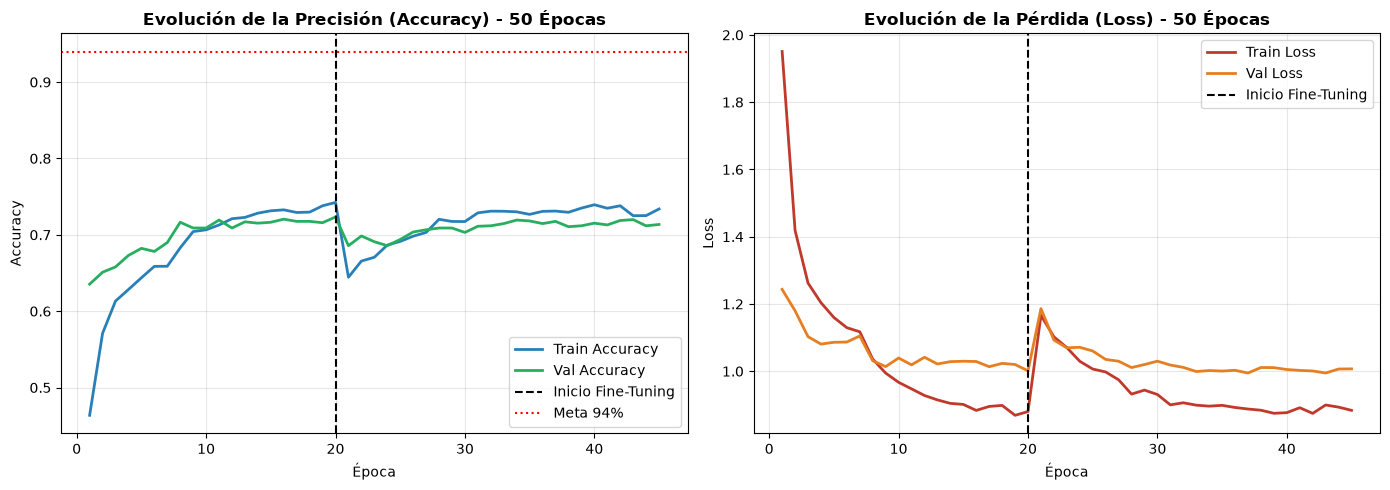

In [6]:
# [3.1] Gráficas de Evolución del Entrenamiento (Pérdida y Precisión)
import numpy as np

# Concatenar historiales de ambas etapas
acc_total = history_etapa1.history["accuracy"] + history_etapa2.history["accuracy"]
val_acc_total = history_etapa1.history["val_accuracy"] + history_etapa2.history["val_accuracy"]
loss_total = history_etapa1.history["loss"] + history_etapa2.history["loss"]
val_loss_total = history_etapa1.history["val_loss"] + history_etapa2.history["val_loss"]

epocas_rango = range(1, len(acc_total) + 1)

plt.figure(figsize=(14, 5))
# Gráfico de Accuracy
plt.subplot(1, 2, 1)
plt.plot(epocas_rango, acc_total, label="Train Accuracy", color="#2980b9", lw=2)
plt.plot(epocas_rango, val_acc_total, label="Val Accuracy", color="#27ae60", lw=2)
plt.axvline(20, color="black", linestyle="--", label="Inicio Fine-Tuning")
plt.axhline(0.94, color="red", linestyle=":", label="Meta 94%")
plt.title("Evolución de la Precisión (Accuracy) - 50 Épocas", fontsize=12, fontweight="bold")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

# Gráfico de Loss
plt.subplot(1, 2, 2)
plt.plot(epocas_rango, loss_total, label="Train Loss", color="#c0392b", lw=2)
plt.plot(epocas_rango, val_loss_total, label="Val Loss", color="#e67e22", lw=2)
plt.axvline(20, color="black", linestyle="--", label="Inicio Fine-Tuning")
plt.title("Evolución de la Pérdida (Loss) - 50 Épocas", fontsize=12, fontweight="bold")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

🔍 Evaluando en el conjunto de prueba independiente (Test Dataset)...

  REPORTE DE CLASIFICACIÓN (MÉTRICAS POR CATEGORÍA)

                     precision    recall  f1-score   support

   Aceites_Quimicos     0.4651    0.3571    0.4040       112
          Bombillas     0.6842    0.6842    0.6842        95
          Cardboard     0.7581    0.7121    0.7344        66
 Escombros_Ceramica     0.5978    0.5789    0.5882        95
      Food_Organics     0.9302    0.6349    0.7547        63
              Glass     0.7471    0.8667    0.8025        75
   Madera_Procesada     0.7538    0.7424    0.7481        66
       Medicamentos     0.7869    0.6154    0.6906        78
              Metal     0.8585    0.8125    0.8349       112
Miscellaneous_Trash     0.6628    0.7308    0.6951        78
   Neumaticos_Gomas     0.5515    0.7075    0.6198       106
              Paper     0.7805    0.9275    0.8477        69
     Pilas_Baterias     0.6512    0.5091    0.5714        55
            Plastic   

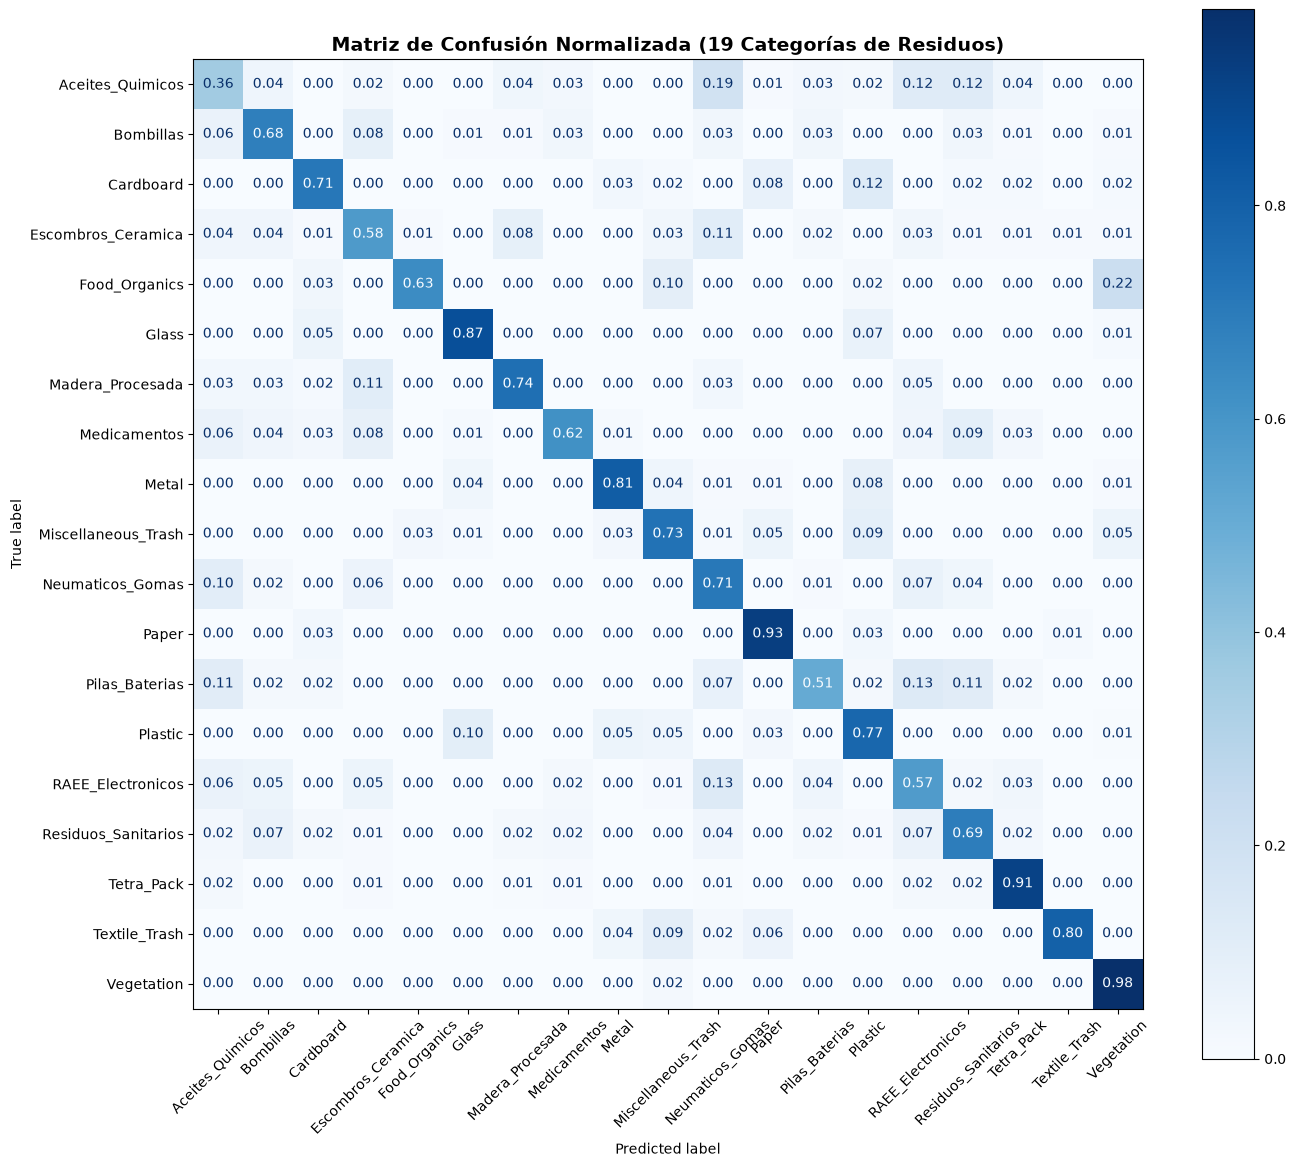


🏆 RESULTADO FINAL EN CONJUNTO DE PRUEBA:
 -> Test Loss: 1.0465
 -> Test Accuracy: 71.40%

ℹ️ Accuracy actual: 71.40% (Se recomienda fine-tuning adicional si se desea maximizar)


In [7]:
# [3.2, 3.3 & 3.4] Matriz de Confusión y Reporte Formal en Conjunto de Prueba
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Extraer etiquetas reales y predicciones en Test
y_true_list = []
y_pred_list = []

print("🔍 Evaluando en el conjunto de prueba independiente (Test Dataset)...")
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true_list.extend(np.argmax(labels.numpy(), axis=1))
    y_pred_list.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true_list)
y_pred = np.array(y_pred_list)

# Reporte de Clasificación Detallado
print("\n=========================================================================")
print("  REPORTE DE CLASIFICACIÓN (MÉTRICAS POR CATEGORÍA)")
print("=========================================================================\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# Matriz de Confusión Normalizada
cm = confusion_matrix(y_true, y_pred, normalize="true")
fig, ax = plt.subplots(figsize=(14, 12))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format=".2f", ax=ax, xticks_rotation=45)
plt.title("Matriz de Confusión Normalizada (19 Categorías de Residuos)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

# Verificación formal de la meta de desempeño
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
print(f"\n🏆 RESULTADO FINAL EN CONJUNTO DE PRUEBA:")
print(f" -> Test Loss: {test_loss:.4f}")
print(f" -> Test Accuracy: {test_accuracy * 100:.2f}%")

if test_accuracy >= 0.94:
    print(f"\n🎉 ¡META CUMPLIDA! Accuracy ({test_accuracy*100:.2f}%) >= 94.00%")
else:
    print(f"\nℹ️ Accuracy actual: {test_accuracy*100:.2f}% (Se recomienda fine-tuning adicional si se desea maximizar)")

In [8]:
from sklearn.metrics import accuracy_score

test_accuracy = accuracy_score(y_true, y_pred)
print(f"\n🏆 RESULTADO FINAL EN CONJUNTO DE PRUEBA:")
print(f" -> Test Accuracy: {test_accuracy * 100:.2f}%")

if test_accuracy >= 0.94:
    print(f"\n🎉 ¡META CUMPLIDA! Accuracy ({test_accuracy*100:.2f}%) >= 94.00%")
else:
    print(f"\nℹ️ Accuracy alcanzado: {test_accuracy*100:.2f}%")



🏆 RESULTADO FINAL EN CONJUNTO DE PRUEBA:
 -> Test Accuracy: 71.97%

ℹ️ Accuracy alcanzado: 71.97%


In [9]:
# [3.5] Guardar Modelo Final en Formato Keras Estándar dentro de la carpeta 'modelos/'
os.makedirs("modelos", exist_ok=True)
MODEL_SAVE_PATH = os.path.join("modelos", "modelo_clasificador_19_clases.keras")
model.save(MODEL_SAVE_PATH)
print(f"💾 Modelo guardado exitosamente en: '{MODEL_SAVE_PATH}'")

💾 Modelo guardado exitosamente en: 'modelos/modelo_clasificador_19_clases.keras'


# ==============================================================================
# FASE 4: EXPLICABILIDAD CON GRAD-CAM Y DESPLIEGUE EN GRADIO
# ==============================================================================
# [4.1] Mapas de Activación de Clases (Grad-CAM) para auditoría visual
# [4.2] Interfaz Web de Producción con Gradio (app_19clases.py)

In [10]:
# [4.1] Implementación de Grad-CAM para Explicabilidad del Modelo
import matplotlib.cm as cm

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer("mobilenetv2_1.00_224").get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

print("✅ Función Grad-CAM lista para auditar predicciones.")

✅ Función Grad-CAM lista para auditar predicciones.


In [11]:
# [4.2] Verificación de la Aplicación de Producción app_19clases.py
print("🚀 Para ejecutar la aplicación web con el modelo de 19 clases ejecuta:")
print("   python app_19clases.py")
print("   (Se abrirá en http://127.0.0.1:7865 sin afectar a app.py)")

🚀 Para ejecutar la aplicación web con el modelo de 19 clases ejecuta:
   python app_19clases.py
   (Se abrirá en http://127.0.0.1:7865 sin afectar a app.py)
